# **AI METHODS I**
## Day IV · Assignment: a church style classifier

| | |
|---|---|
| **Team 5** | Soumyajyoti Datta, Sindhuja Davuluri, Breno Sader, Diego Alpízar |
| **Course** | AI Methods I: Machine Learning for the Built Environment (IAAC MaAI 2026/27) |
| **Track** | **B**: church style classifier (pretrained CNN approach) |
| **Model on Hugging Face** | [iaac-maai/day4_team5_church_style_classifier](https://huggingface.co/iaac-maai/day4_team5_church_style_classifier) |

This notebook trains a **convolutional neural network** that looks at a photo of a church and predicts its **architectural style**: Romanesque, Gothic, Renaissance, Baroque, Classical (Neoclassical) or Modern.

It reuses the methods of the three class notebooks:

| Notebook | What we reuse |
|---|---|
| 01 · Neural network fundamentals | Tensors, the training loop, training curves, early stopping, saving and reloading a model |
| 02 · Computer vision with OpenCV | Images as arrays (height × width × channels) |
| 03 · Object detection with YOLO and SAM | Transfer learning from a pretrained CNN, per-class evaluation and the confusion matrix |

# 0. Introduction and problem definition

## 0.1 Use case

| Question | Our answer |
|---|---|
| **Who would use this model, and for what?** | A heritage office, an architecture archive or a research team with **thousands of untagged photos of churches** (for example uploads to Wikimedia Commons, or a regional heritage survey) that wants to **pre-sort them by style**, so that experts check the right folders first. |
| **What does a mistake cost?** | Low to moderate: a wrong style puts a photo in the wrong folder, and an expert corrects it later. The real risk is a **confident** mistake that nobody checks, so the model must report its **probability**, and low-confidence photos go to a human. |
| **What would be good enough?** | Clearly better than the **majority-class baseline** on every style, and good enough on the **rare styles** (Renaissance, Classical) that they are not systematically mislabelled as the frequent ones. |

## 0.2 The data

| | |
|---|---|
| **Dataset** | **WikiChurches** (Barz and Denzler, NeurIPS 2021 Datasets and Benchmarks), subset **WikiChurches-6** |
| **Source** | [Zenodo, DOI 10.5281/zenodo.5166987](https://doi.org/10.5281/zenodo.5166987) · [paper](https://arxiv.org/abs/2108.06959) |
| **Licence** | Dataset **CC BY-SA 4.0**. Every image comes from **Wikimedia Commons** with its own free licence (CC BY-SA, CC BY, CC0, public domain…), listed with its author in `image_meta.json`. |
| **Size** | 8,488 photos of church exteriors in 6 styles, with **official train / validation / test splits**. We use a reproducible subset of 2,646 images (section 1.4). |
| **One example** | One RGB photo of one church, with **one style label** taken from Wikidata. |

## 0.3 Table of contents
0. Introduction and setup
1. Data and splits
2. Baseline
3. The model and its training
4. Look inside and diagnose
5. Tuning: two experiments on the validation set
6. The test set, used once
7. Application: six new churches
8. Save, reload and use
9. Conclusions

## 0.4 Setup

### Libraries

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install torch torchvision torchinfo pandas matplotlib seaborn scikit-learn pillow requests tqdm huggingface_hub

In [2]:
import copy
import io
import json
import random
import re
import shutil
import struct
import threading
import time
import zipfile
import zlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from torchinfo import summary
from PIL import Image, ImageOps
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download

D:\MaAI IAAC\Term 1\AI Methods\5-day4-assignment\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Folders

The notebook lives in `notebook/`, so the other folders of the repository are **one level up**.

In [3]:
# Find this track from the repository root, track folder, or notebook folder.
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "notebook" / "neural_network.ipynb").is_file():
        TRACK_DIR = candidate
        break
    if (candidate / "trackB" / "notebook" / "neural_network.ipynb").is_file():
        TRACK_DIR = candidate / "trackB"
        break
else:
    raise FileNotFoundError("Cannot find the trackB assignment folder")

DATA_DIR = TRACK_DIR / "data"
FIG_DIR = TRACK_DIR / "figures"
MODEL_DIR = TRACK_DIR / "models"
META_DIR = DATA_DIR / "wikichurches"        # labels, style names and image metadata
IMAGE_DIR = DATA_DIR / "images"             # resized images, one folder per split and class
NEW_IMAGE_DIR = DATA_DIR / "new_images"     # photos for the application (section 7)

for folder in [DATA_DIR, FIG_DIR, MODEL_DIR, META_DIR, NEW_IMAGE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
    print(f"{str(folder):<26} -> {folder.resolve()}")
# Reuse the ImageNet weights already cached for this track.
torch.hub.set_dir(str(DATA_DIR / "cache" / "torch_cache" / "hub"))


..\data                    -> D:\MaAI IAAC\Term 1\AI Methods\5-day4-assignment\data
..\figures                 -> D:\MaAI IAAC\Term 1\AI Methods\5-day4-assignment\figures
..\models                  -> D:\MaAI IAAC\Term 1\AI Methods\5-day4-assignment\models
..\data\wikichurches       -> D:\MaAI IAAC\Term 1\AI Methods\5-day4-assignment\data\wikichurches
..\data\new_images         -> D:\MaAI IAAC\Term 1\AI Methods\5-day4-assignment\data\new_images


### Random seed

Networks start from random weights and see the images in a random order. Fixing the seed gives everybody the same results (notebook 01).

In [4]:
RANDOM_STATE = 42


def set_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

### Which processor will do the work?

In [5]:
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print(f"PyTorch {torch.__version__}, device: {DEVICE}")
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch 2.14.1+cu126, device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


### Settings

| Setting | Meaning |
|---|---|
| `TRAIN` | `None` = train only if a GPU is available. Without a GPU, the notebook downloads our published model and training logs from Hugging Face, so it still runs on any laptop (as in notebook 03). |
| `RETRAIN` | `True` = train again even if `models/model.pt` already exists |
| `TRAIN_CAP`, `TEST_CAP` | At most this many training / test images per class (section 1.4) |
| `SHORT_SIDE` | Images are stored with their short side resized to 256 pixels |

In [6]:
TRAIN = None
RETRAIN = False
HF_REPO = "iaac-maai/day4_team5_church_style_classifier"
TRAIN_CAP = 300
TEST_CAP = 150
SHORT_SIDE = 256
ZENODO = "https://zenodo.org/api/records/5166987/files"
HEADERS = {"User-Agent": "IAAC-AI-Methods-course/1.0 (educational use)"}   # servers ask programs to identify themselves

if TRAIN is None:
    TRAIN = DEVICE != "cpu"
print("Plan:", "train the models" if TRAIN else f"download the published model and logs from {HF_REPO}")

Plan: train the models


### Plot settings and a helper to save figures

Every figure is saved to `figures/`; the ones for the model card are also copied to `models/`.

In [7]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)


def save_fig(name, model_card_name=None):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    message = f"Figure saved to {path}"
    if model_card_name:
        shutil.copy(path, MODEL_DIR / f"{model_card_name}.png")
        message += f" and models/{model_card_name}.png"
    print(message)

# 1. Data and splits

## 1.1 Download the labels and the image metadata

WikiChurches is published on Zenodo as a few small files and one large `images.zip` (12.4 GB). We start with the small ones:

| File | What it contains |
|---|---|
| `labels.zip` | The official splits: one text file per split, one line per image (`file style_id`) |
| `style_names.txt` | The name of every style (`style_id name`) |
| `image_meta.json` | For every image: original URL, **author** and **licence** on Wikimedia Commons |
| `churches.json` | For every church: name, styles, **country**, construction year |

A small helper downloads a file once and keeps it in `data/`:

In [8]:
def download(url, path, retries=5):
    # Download a file once (cached), retrying with a growing pause if the server is busy
    path = Path(path)
    if path.exists():
        return path
    for attempt in range(retries):
        response = requests.get(url, headers=HEADERS, timeout=300)
        if response.ok:
            path.write_bytes(response.content)
            return path
        time.sleep(5 * (attempt + 1))
    response.raise_for_status()

In [9]:
for name in ["labels.zip", "style_names.txt", "image_meta.json", "churches.json"]:
    path = download(f"{ZENODO}/{name}/content", META_DIR / name)
    print(f"{name:>16}: {path.stat().st_size / 1e6:5.1f} MB")

with zipfile.ZipFile(META_DIR / "labels.zip") as archive:
    archive.extractall(META_DIR)
print("\nSplit files:", sorted(p.name for p in (META_DIR / "labels").glob("wc6*.txt")))

      labels.zip:   0.3 MB
 style_names.txt:   0.0 MB
 image_meta.json:  37.7 MB
   churches.json:   3.4 MB

Split files: ['wc6.txt', 'wc6_test.txt', 'wc6_train.txt', 'wc6_trainval.txt', 'wc6_val.txt']


## 1.2 What is inside?

### The style names

In [10]:
style_names = dict(line.split(" ", 1) for line in (META_DIR / "style_names.txt").read_text(encoding="utf-8").splitlines() if line.strip())
print(f"{len(style_names)} styles in the full dataset, for example:")
list(style_names.items())[:8]

121 styles in the full dataset, for example:


[('Q578577', 'Early English Gothic'),
 ('Q12049741', 'Romantic Architecture'),
 ('Q966571', 'Byzantine Revival Architecture'),
 ('Q6092662', 'Italian Baroque'),
 ('Q2884586', 'Italian Romanesque Architecture'),
 ('Q47942', 'Functionalism'),
 ('Q616753', 'Naryshkin Baroque'),
 ('Q2864731', 'Romanesque Architecture of Provence')]

### The metadata of one image

Every image keeps the author and licence it has on Wikimedia Commons. We need them to credit the photos shown in our figures.

In [11]:
image_meta = json.loads((META_DIR / "image_meta.json").read_text(encoding="utf-8"))
example_file = next(iter(image_meta))
example_meta = image_meta[example_file]["extmetadata"]

print(f"Metadata for {len(image_meta):,} images. Example: {example_file}")
for key in ["ObjectName", "Artist", "LicenseShortName", "DateTime"]:
    value = re.sub(r"<[^>]+>", "", example_meta.get(key, {}).get("value", ""))
    print(f"  {key:<17} {value[:70]}")

Metadata for 9,502 images. Example: Q16550866_wd0.jpg
  ObjectName        Duomo e campanile di Cologna Veneta (VR)
  Artist            Ricklen
  LicenseShortName  CC BY-SA 3.0
  DateTime          2012-07-05 20:49:41


### The metadata of one church

In [12]:
churches = json.loads((META_DIR / "churches.json").read_text(encoding="utf-8"))
example_church = churches[example_file.split("_wd")[0]]
print(f"Metadata for {len(churches):,} churches. Example:")
example_church

Metadata for 9,346 churches. Example:


{'id': 'Q16550866',
 'name': 'Duomo di Cologna Veneta',
 'built_year': 1821,
 'styles': ['Q6092863'],
 'country': {'id': 'Q38', 'name': 'Italy'},
 'location': {'lat': 45.30984, 'lon': 11.38344}}

## 1.3 The official splits

**We split before anything else.** WikiChurches-6 comes with **official training, validation and test splits**. One line per image: the file name and the Wikidata ID of its style. We give each style a short name, and keep the **church** each photo belongs to (the part of the file name before `_wd`).

In [13]:
CLASS_SLUGS = {"Baroque": "baroque", "Classical Architecture": "classical", "Gothic": "gothic",
               "Modern Architecture": "modern", "Renaissance": "renaissance", "Romanesque": "romanesque"}


def read_split(split):
    rows = [line.split() for line in (META_DIR / "labels" / f"wc6_{split}.txt").read_text().splitlines() if line.strip()]
    df = pd.DataFrame(rows, columns=["file", "style_id"])
    df["style"] = df["style_id"].map(style_names).map(CLASS_SLUGS)
    df["church"] = df["file"].str.split("_wd").str[0]
    df["split"] = split
    return df


official = pd.concat([read_split(s) for s in ["train", "val", "test"]], ignore_index=True)
print(f"{len(official):,} images, {official['church'].nunique():,} churches")
official.head()

8,488 images, 8,362 churches


,file,style_id,style,church,split
0,Q21716735_wd0.jpg,Q840829,baroque,Q21716735,train
1,Q20730233_wd0.jpg,Q840829,baroque,Q20730233,train
2,Q2317509_wd0.jpg,Q840829,baroque,Q2317509,train
3,Q1897745_wd0.jpg,Q840829,baroque,Q1897745,train
4,Q20754132_wd0.jpg,Q840829,baroque,Q20754132,train


### Check: is the split made by church?

Several photos can show the **same church**. If one of them is in the training set and another in the test set, the model can recognise the *building* instead of learning its *style*, and the test score is too optimistic (leakage, Day 2). The official splits are made by church; let's check it.

In [14]:
churches_per_split = official.groupby("split")["church"].apply(set)
print("Churches in train and test:      ", len(churches_per_split["train"] & churches_per_split["test"]))
print("Churches in train and validation:", len(churches_per_split["train"] & churches_per_split["val"]))
print("Churches in validation and test: ", len(churches_per_split["val"] & churches_per_split["test"]))

Churches in train and test:       0
Churches in train and validation: 0
Churches in validation and test:  0


### Keep only images with a known licence

In [15]:
def licence_of(file):
    return image_meta.get(file, {}).get("extmetadata", {}).get("LicenseShortName", {}).get("value")


official["licence"] = official["file"].map(licence_of)
print("Images without licence metadata (dropped):", official["licence"].isna().sum())
official = official[official["licence"].notna()]

Images without licence metadata (dropped): 26


## 1.4 Our subset

The official splits are very **imbalanced** (3,041 Gothic but only 64 Renaissance training images), and all 8,488 images weigh 11 GB. We keep the official split of every image but **subsample inside each split**, with a fixed seed:

| Split | Images per class |
|---|---|
| train | at most 300 (the rare classes keep all their images) |
| validation | all (about 50 per class) |
| test | at most 150 |

In [16]:
CAPS = {"train": TRAIN_CAP, "val": None, "test": TEST_CAP}
parts = []
for (split, style), group in official.groupby(["split", "style"]):
    cap = CAPS[split]
    parts.append(group if cap is None or len(group) <= cap else group.sample(cap, random_state=RANDOM_STATE))
data = pd.concat(parts).sort_values(["split", "style", "file"]).reset_index(drop=True)

counts = pd.concat({"official": pd.crosstab(official["style"], official["split"]),
                    "used": pd.crosstab(data["style"], data["split"])}, axis=1)
counts = counts[[(k, s) for k in ["official", "used"] for s in ["train", "val", "test"]]]
print(f"Images used: {len(data):,} of {len(official):,}")
counts

Images used: 2,646 of 8,462


official           used         
split          train val test train val test
style                                       
baroque         1076  52  370   300  52  150
classical        288  50  112   288  50  112
gothic          3034  52  504   300  52  150
modern           330  50  127   300  50  127
renaissance       64  52   99    64  52   99
romanesque      1648  50  504   300  50  150

## 1.5 Download only the images we need

### The idea

Instead of downloading the whole 12.4 GB archive, we read it **remotely**:
1. A ZIP file keeps an **index** of its contents at its end, and the Zenodo server can send any **range of bytes** of a file.
2. We read the index (a few hundred kilobytes), then download **only the images of our subset**, with one request per image.
3. Each image is resized so that its short side is 256 pixels (the network uses 224 × 224 crops) and saved as a small JPEG in `data/images/<split>/<class>/`, the layout that `torchvision.datasets.ImageFolder` expects.

About 3.5 GB is transferred once, and less than 100 MB stays on disk.

### A file that lives on a server

`zipfile` can read any object that behaves like a file (`read`, `seek`, `tell`). This small class does that with HTTP range requests:

In [17]:
class HTTPRangeFile:
    # A read-only, seekable file over HTTP range requests, with a small read-ahead cache
    def __init__(self, url, block=1 << 20):
        self.url, self.block, self.pos = url, block, 0
        self.session = requests.Session()
        response = self.session.get(url, headers={"Range": "bytes=0-0", **HEADERS}, timeout=60)
        self.size = int(response.headers["Content-Range"].split("/")[1])
        self.cache_start, self.cache = 0, b""

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, offset, whence=0):
        self.pos = {0: offset, 1: self.pos + offset, 2: self.size + offset}[whence]
        return self.pos

    def read(self, n=-1):
        if n is None or n < 0:
            n = self.size - self.pos
        n = min(n, self.size - self.pos)
        if n <= 0:
            return b""
        if not (self.cache_start <= self.pos and self.pos + n <= self.cache_start + len(self.cache)):
            end = min(self.size, self.pos + max(n, self.block)) - 1
            response = self.session.get(self.url, headers={"Range": f"bytes={self.pos}-{end}", **HEADERS}, timeout=120)
            self.cache_start, self.cache = self.pos, response.content
        offset = self.pos - self.cache_start
        chunk = self.cache[offset:offset + n]
        self.pos += len(chunk)
        return chunk

### Read the index of the archive

In [18]:
ZIP_URL = f"{ZENODO}/images.zip/content"

start = time.time()
archive = zipfile.ZipFile(HTTPRangeFile(ZIP_URL))
members = {Path(info.filename).name: info for info in archive.infolist()}
print(f"Index read in {time.time() - start:.1f} s: {len(members):,} files in images.zip "
      f"({sum(i.compress_size for i in members.values()) / 1e9:.1f} GB)")

needed = sum(members[f].compress_size for f in data["file"])
print(f"Our subset: {len(data):,} images, {needed / 1e9:.1f} GB to transfer")

Index read in 2.1 s: 9,503 files in images.zip (12.4 GB)
Our subset: 2,646 images, 3.6 GB to transfer


### Download one image with one request

The index tells us where every image starts inside the archive and how many bytes it has, so **one request per image** is enough. Zenodo allows at most **133 requests per minute** from one computer: `wait_for_slot` spreads the requests evenly (125 per minute), and if the server still asks us to wait, we wait as long as it says.

In [19]:
REQUESTS_PER_MINUTE = 125          # Zenodo's limit is 133 per minute
_lock = threading.Lock()
_next_slot = [0.0]
_local = threading.local()         # one connection per download thread


def wait_for_slot():
    # Give every request its own time slot, 60 / 125 = 0.48 seconds apart
    with _lock:
        now = time.monotonic()
        slot = max(now, _next_slot[0])
        _next_slot[0] = slot + 60 / REQUESTS_PER_MINUTE
    time.sleep(max(0.0, slot - now))


def get_range(start, end):
    # Download the bytes start..end of images.zip, respecting the rate limit
    if not hasattr(_local, "session"):
        _local.session = requests.Session()
    for attempt in range(10):
        wait_for_slot()
        response = _local.session.get(ZIP_URL, headers={**HEADERS, "Range": f"bytes={start}-{end}"}, timeout=120)
        if response.status_code == 206:
            return response.content
        time.sleep(int(response.headers.get("retry-after", 10)))      # rate limit reached: wait as the server asks
    raise RuntimeError(f"Could not download bytes {start}-{end}")

In [20]:
def read_member(info):
    # The local header of the file (30 bytes + its name + extra fields), then the compressed image
    start = info.header_offset
    chunk = get_range(start, start + 30 + len(info.orig_filename.encode()) + 256 + info.compress_size - 1)
    name_length, extra_length = struct.unpack("<HH", chunk[26:30])
    data_start = 30 + name_length + extra_length
    data = chunk[data_start:data_start + info.compress_size]
    if len(data) < info.compress_size:                                   # rare: a longer header than expected
        data += get_range(start + len(chunk), start + data_start + info.compress_size - 1)
    return data if info.compress_type == zipfile.ZIP_STORED else zlib.decompress(data, -15)


def image_path(row):
    return IMAGE_DIR / row.split / row.style / row.file


def fetch(row):
    # Download one image, resize it so that its short side is 256 px, and save it as a JPEG
    out = image_path(row)
    if out.exists():
        return 0
    raw = read_member(members[row.file])
    image = ImageOps.exif_transpose(Image.open(io.BytesIO(raw))).convert("RGB")
    scale = SHORT_SIDE / min(image.size)
    if scale < 1:
        image = image.resize((round(image.width * scale), round(image.height * scale)), Image.BICUBIC)
    out.parent.mkdir(parents=True, exist_ok=True)
    image.save(out, "JPEG", quality=90)
    return len(raw)

### Download the whole subset

Four downloads run in parallel, so that the time slots are always used. The first run takes about **20 minutes** (2,646 images at about 125 per minute); afterwards the images are on disk and the cell finishes immediately.

In [21]:
todo = [row for row in data.itertuples() if not image_path(row).exists()]
start = time.time()
if todo:
    with ThreadPoolExecutor(max_workers=4) as pool:
        downloaded = list(tqdm(pool.map(fetch, todo), total=len(todo), desc="Downloading images"))
    print(f"Downloaded {len(todo):,} images ({sum(downloaded) / 1e9:.2f} GB) in {(time.time() - start) / 60:.1f} min")

stored = list(IMAGE_DIR.rglob("*.jpg"))
print(f"{len(stored):,} images on disk, {sum(p.stat().st_size for p in stored) / 1e6:.0f} MB")

2,646 images on disk, 75 MB


### An image is an array

As in notebook 02: a colour image is an array of shape **height × width × 3**, with values from 0 to 255. Ours have a short side of 256 pixels.

Q1017323_wd0.jpg (baroque): shape (256, 384, 3), dtype uint8, values 0–255


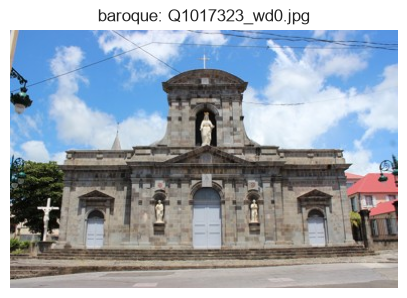

In [22]:
first = next(data.itertuples())
image = Image.open(image_path(first))
array = np.asarray(image)
print(f"{first.file} ({first.style}): shape {array.shape}, dtype {array.dtype}, values {array.min()}–{array.max()}")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"{first.style}: {first.file}")
plt.axis("off")
plt.show()

## 1.6 Look at the data

### Images per style and split

Figure saved to ..\figures\01_class_counts.png


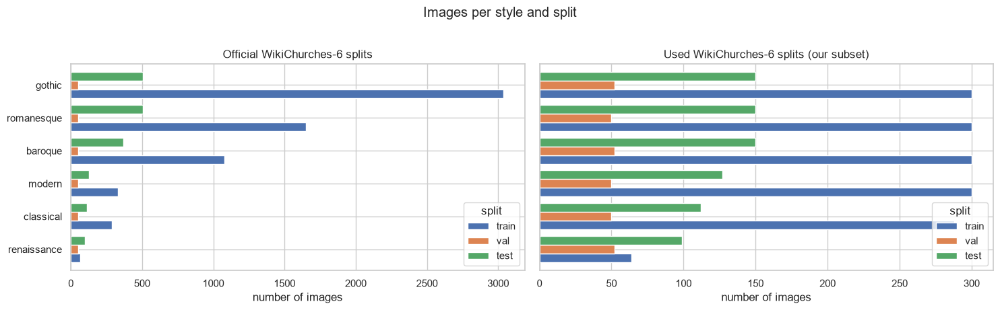

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
order = counts[("official", "train")].sort_values().index
for ax, kind in zip(axes, ["official", "used"]):
    counts[kind].loc[order, ["train", "val", "test"]].plot.barh(ax=ax, width=0.8)
    ax.set_title(f"{kind.capitalize()} WikiChurches-6 splits" + (" (our subset)" if kind == "used" else ""))
    ax.set_xlabel("number of images")
    ax.set_ylabel("")
plt.suptitle("Images per style and split", y=1.02)
plt.tight_layout()
save_fig("01_class_counts")
plt.show()

> **Reading (team):** *What do you notice about the balance of the classes, before and after subsampling? Which class will be the hardest, and why?*

### Five photos per style

The authors and licences of every photo shown in a figure are collected in `FIGURE_CREDITS` and exported with the model card (section 8), as their licences require.

In [24]:
FIGURE_CREDITS = []
CLASSES = sorted(CLASS_SLUGS.values())     # the order used by ImageFolder (alphabetical)


def clean_html(text):
    return re.sub(r"<[^>]+>", "", text or "").strip()


def credit(file, figure):
    # Remember the author and licence of an image shown in a figure
    meta = image_meta.get(file, {})
    ext = meta.get("extmetadata", {})
    FIGURE_CREDITS.append({"figure": figure, "file": file, "author": clean_html(ext.get("Artist", {}).get("value")),
                           "licence": ext.get("LicenseShortName", {}).get("value"), "source": meta.get("descriptionurl")})

Figure saved to ..\figures\02_class_examples.png and models/class_examples.png


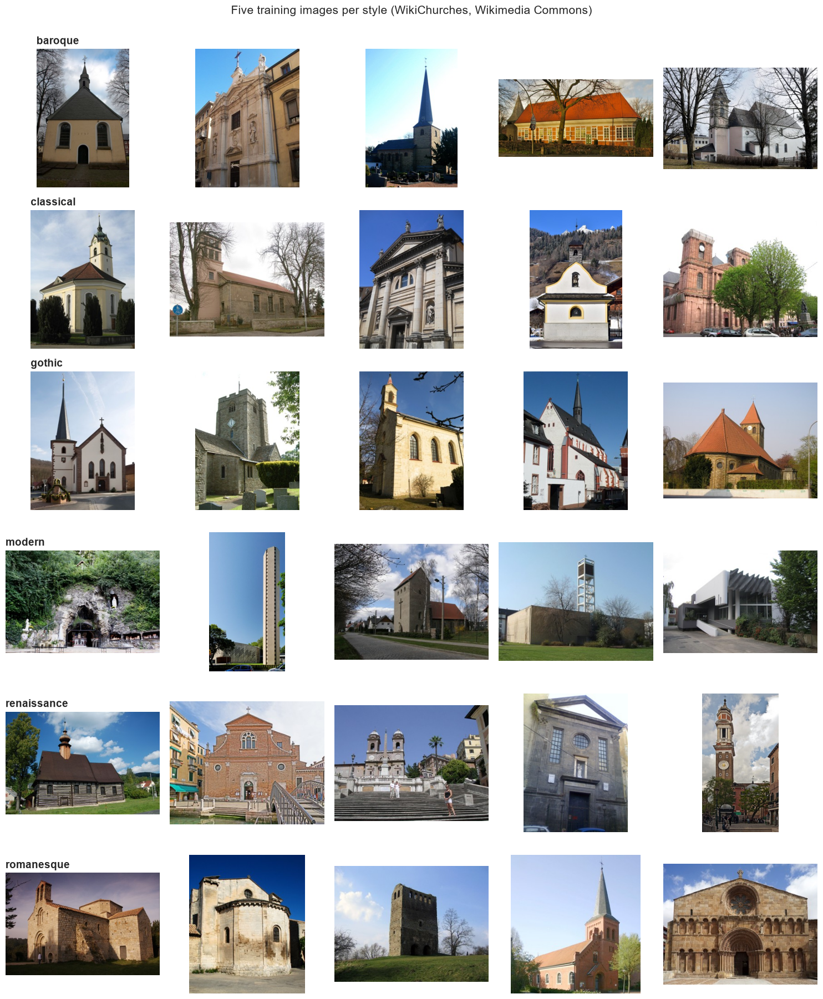

In [25]:
examples = data[data["split"] == "train"].groupby("style").sample(5, random_state=RANDOM_STATE)

fig, axes = plt.subplots(len(CLASSES), 5, figsize=(15, 3 * len(CLASSES)))
for r, style in enumerate(CLASSES):
    for c, row in enumerate(examples[examples["style"] == style].itertuples()):
        axes[r, c].imshow(Image.open(image_path(row)))
        axes[r, c].set_axis_off()
        credit(row.file, "class_examples")
    axes[r, 0].set_title(style, loc="left", fontsize=14, fontweight="bold")
plt.suptitle("Five training images per style (WikiChurches, Wikimedia Commons)", y=1.0, fontsize=15)
plt.tight_layout()
save_fig("02_class_examples", "class_examples")
plt.show()

## 1.7 Licences and coverage

Two facts for the model card: the **licences** of our images, and **where** the churches are. The model will only know the kind of churches it has seen.

### Licences

In [26]:
licences = data["licence"].value_counts()
print(f"{len(licences)} different licence labels, all free licences of Wikimedia Commons. The 10 most common:")
licences.head(10)

35 different licence labels, all free licences of Wikimedia Commons. The 10 most common:


licence
CC BY-SA 3.0       1130
Public domain       302
CC BY-SA 4.0        272
CC-BY-SA-3.0        231
CC BY 3.0           169
CC0                 121
CC BY-SA 2.0        100
CC BY-SA 2.5         66
CC BY-SA 3.0 de      52
CC BY 2.5            46
Name: count, dtype: int64

### Countries

In [27]:
data["country"] = data["church"].map(lambda q: (churches.get(q, {}).get("country") or {}).get("name", "unknown"))
(data["country"].value_counts(normalize=True).head(10) * 100).round(1).rename("% of images")

country
Germany           42.4
Italy              9.6
France             9.2
Austria            6.1
Czech Republic     5.5
Spain              5.1
United Kingdom     5.0
Switzerland        3.4
Belgium            3.1
Belarus            1.6
Name: % of images, dtype: float64

### Construction year per style

A quick check that the labels make sense: Romanesque churches should be the oldest and Modern ones the newest.

Figure saved to ..\figures\03_built_year.png


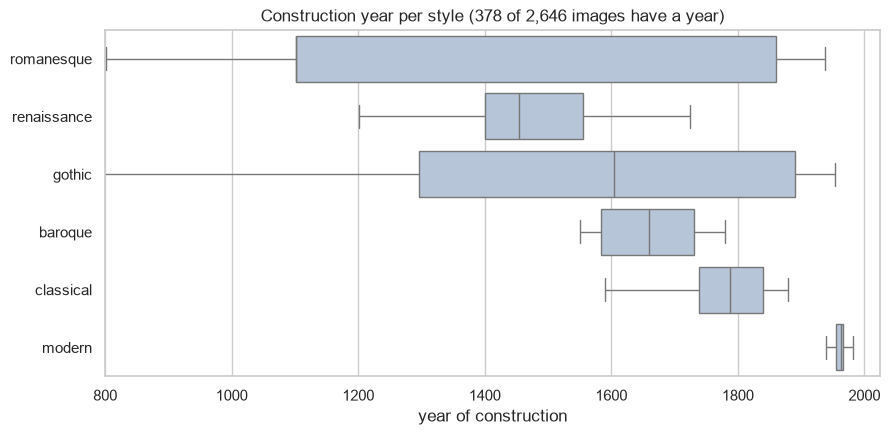

In [28]:
data["built_year"] = data["church"].map(lambda q: churches.get(q, {}).get("built_year"))
known = data.dropna(subset=["built_year"])
order_by_year = known.groupby("style")["built_year"].median().sort_values().index

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=known, x="built_year", y="style", order=order_by_year, color="lightsteelblue", showfliers=False)
plt.xlim(800, 2025)
plt.title(f"Construction year per style ({len(known):,} of {len(data):,} images have a year)")
plt.xlabel("year of construction")
plt.ylabel("")
save_fig("03_built_year")
plt.show()

# 2. Baseline

The simplest possible "model" always predicts the **most common class of the training set**. A network has to beat it clearly to be worth its complexity (Day 2).

We report three metrics:

| Metric | Question |
|---|---|
| **Accuracy** | What share of the photos is classified correctly? |
| **Balanced accuracy** | The mean recall over the classes: are *all* styles recognised, not only the frequent ones? |
| **Macro F1** | The mean F1 over the classes: precision and recall, every style counting the same |

In [29]:
train_counts = data[data["split"] == "train"]["style"].value_counts()
MAJORITY = train_counts.sort_index().idxmax()      # ties are broken alphabetically
print("Training images per class:", train_counts.to_dict())
print("Majority class:", MAJORITY)

Training images per class: {'baroque': 300, 'gothic': 300, 'modern': 300, 'romanesque': 300, 'classical': 288, 'renaissance': 64}
Majority class: baroque


In [30]:
def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0)}


val_true = data[data["split"] == "val"]["style"]
baseline_val = scores(val_true, [MAJORITY] * len(val_true))
pd.DataFrame({"majority baseline (validation)": baseline_val}).round(3)

,majority baseline (validation)
accuracy,0.170
balanced accuracy,0.167
macro F1,0.048


# 3. The model and its training

## 3.1 Preparing the images

A **ResNet18** pretrained on ImageNet expects 224 × 224 images, normalised with the ImageNet mean and standard deviation. `weights.transforms()` does exactly that.

⚠️ **Watch out:** the same transforms must also be used at **prediction time**. A model fed with images prepared differently from training gives nonsense.

In [31]:
weights = models.ResNet18_Weights.DEFAULT
eval_tf = weights.transforms()          # resize to 256, centre crop 224, normalise as in pretraining
eval_tf

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

### Data augmentation

For training we add **random changes**: a random crop of 70–100 % of the photo, a horizontal flip, small brightness and contrast changes. The network sees a slightly different version of every photo at every epoch, which works against overfitting: a church does not change style when it is photographed a bit closer or on a cloudier day.

In [32]:
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(eval_tf.mean, eval_tf.std),
])
train_tf

Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.7, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

### The same photo, augmented five times

Figure saved to ..\figures\04_augmentation.png


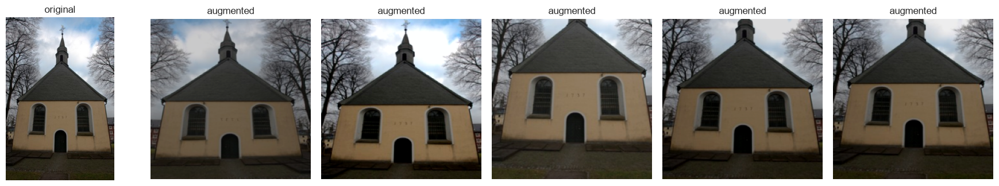

In [33]:
def to_image(tensor):
    # Undo the normalisation to show a tensor as an image
    return (tensor.permute(1, 2, 0).numpy() * np.array(eval_tf.std) + np.array(eval_tf.mean)).clip(0, 1)


aug_row = next(examples.itertuples())
photo = Image.open(image_path(aug_row))
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
axes[0].imshow(photo)
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(to_image(train_tf(photo)))
    ax.set_title("augmented")
for ax in axes:
    ax.set_axis_off()
credit(aug_row.file, "augmentation")
plt.tight_layout()
save_fig("04_augmentation")
plt.show()

### Datasets and data loaders

`ImageFolder` reads one folder per class; the class order is alphabetical. A `DataLoader` cuts the training set into shuffled **batches** of 32 images, a new order at every epoch (notebook 01, section 4.2).

In [34]:
train_ds = datasets.ImageFolder(IMAGE_DIR / "train", transform=train_tf)
val_ds = datasets.ImageFolder(IMAGE_DIR / "val", transform=eval_tf)
test_ds = datasets.ImageFolder(IMAGE_DIR / "test", transform=eval_tf)
assert train_ds.classes == CLASSES == val_ds.classes == test_ds.classes

loader_options = {"num_workers": 2, "pin_memory": True, "persistent_workers": True} if DEVICE == "cuda" else {}

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(RANDOM_STATE), **loader_options)
val_loader = DataLoader(val_ds, batch_size=64, **loader_options)
test_loader = DataLoader(test_ds, batch_size=64, **loader_options)

print("Classes (output order):", CLASSES)
print(f"train {len(train_ds)}, validation {len(val_ds)}, test {len(test_ds)} images; {len(train_loader)} batches per epoch")

Classes (output order): ['baroque', 'classical', 'gothic', 'modern', 'renaissance', 'romanesque']
train 1552, validation 306, test 788 images; 49 batches per epoch


In [35]:
xb, yb = next(iter(train_loader))
print(f"One batch: images {tuple(xb.shape)} {xb.dtype}, labels {tuple(yb.shape)} {yb.dtype}")
print("Labels in this batch:", [CLASSES[i] for i in yb[:8]], "...")

One batch: images (32, 3, 224, 224) torch.float32, labels (32,) torch.int64
Labels in this batch: ['romanesque', 'classical', 'baroque', 'romanesque', 'romanesque', 'baroque', 'romanesque', 'renaissance'] ...


## 3.2 The architecture: a pretrained ResNet18 with a new last layer

**Transfer learning** (notebook 03, section 1): the weights of ResNet18 already know edges, textures and parts from 1.2 million ImageNet photos. We **freeze** them and replace the last layer, which spoke ImageNet's 1,000 classes, by a new `nn.Linear(512, 6)` for our six styles. Only this layer learns.

In [36]:
def build_model(pretrained=True):
    # ResNet18 with every pretrained layer frozen and a new, trainable last layer for our classes
    model = models.resnet18(weights=weights if pretrained else None)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model

In [37]:
print(summary(build_model(), input_size=(1, 3, 224, 224), depth=1,
              col_names=["input_size", "output_size", "num_params", "trainable"], verbose=0))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
ResNet                                   [1, 3, 224, 224]          [1, 6]                    --                        Partial
├─Conv2d: 1-1                            [1, 3, 224, 224]          [1, 64, 112, 112]         (9,408)                   False
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         [1, 64, 112, 112]         (128)                     False
├─ReLU: 1-3                              [1, 64, 112, 112]         [1, 64, 112, 112]         --                        --
├─MaxPool2d: 1-4                         [1, 64, 112, 112]         [1, 64, 56, 56]           --                        --
├─Sequential: 1-5                        [1, 64, 56, 56]           [1, 64, 56, 56]           (147,968)                 False
├─Sequential: 1-6                        [1, 64, 56, 56]           [1, 128, 28, 28]          (525,568)                 False


In [38]:
example_model = build_model()
total = sum(p.numel() for p in example_model.parameters())
trainable = sum(p.numel() for p in example_model.parameters() if p.requires_grad)
print(f"{total:,} parameters, of which {trainable:,} trainable ({trainable / total:.3%}): 512 × 6 weights + 6 biases")

11,179,590 parameters, of which 3,078 trainable (0.028%): 512 × 6 weights + 6 biases


## 3.3 The training loop

The loop of notebook 01, section 4.3, split into three small functions.

### One pass over the data

`run_epoch` trains when it gets an optimizer and only evaluates otherwise. One detail: the frozen **BatchNorm** layers stay in evaluation mode, so that their statistics from ImageNet do not drift on our small training set.

In [39]:
def set_train_mode(model, training):
    model.train(training)
    if training:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d) and not any(p.requires_grad for p in module.parameters()):
                module.eval()       # frozen BatchNorm: keep the ImageNet statistics


def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    set_train_mode(model, training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)                     # 1. forward
            loss = loss_fn(out, yb)             # 2. loss
            if training:
                optimizer.zero_grad()
                loss.backward()                 # 3. backward
                optimizer.step()                # 4. step
            total_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

### Training with early stopping

`train` records the training and validation loss and accuracy after every epoch, stops when the validation loss has not improved for 4 epochs (**early stopping**, notebook 01, section 5) and goes back to the best weights.

In [40]:
def train(model, optimizer, epochs, loss_fn=None, patience=4, name="model"):
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    val_loss_fn = nn.CrossEntropyLoss()        # always the plain loss on validation, so runs are comparable
    history, best_loss, best_state, best_epoch, waited = [], np.inf, None, 0, 0
    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, val_loss_fn)
        history.append({"experiment": name, "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "train_acc": train_acc, "val_acc": val_acc, "seconds": time.time() - start})
        print(f"{name:<22} epoch {epoch:>2}: train loss {train_loss:.3f}, acc {train_acc:.1%} | "
              f"val loss {val_loss:.3f}, acc {val_acc:.1%}")
        if val_loss < best_loss - 1e-4:
            best_loss, best_state, best_epoch, waited = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            waited += 1
            if waited >= patience:
                print(f"Early stopping: no improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)
    print(f"Restored the weights of epoch {best_epoch} (validation loss {best_loss:.3f})")
    return pd.DataFrame(history)

### Predicting a whole data set

`predict` returns the true labels and the predicted **probabilities** (softmax) for every image of a loader.

In [41]:
def predict(model, loader):
    set_train_mode(model, False)
    y_true, probs = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(torch.softmax(model(xb.to(DEVICE)), dim=1).cpu())
            y_true.append(yb)
    return torch.cat(y_true).numpy(), torch.cat(probs).numpy()

## 3.4 Train the main model: frozen backbone

| Setting | Value |
|---|---|
| Optimizer | Adam (notebook 01, section 3) |
| Learning rate | 0.001 for the new layer |
| Batch size | 32 |
| Epochs | at most 20, early stopping with patience 4 |

Without a GPU (`TRAIN = False`), the cell downloads our published weights and training logs from Hugging Face instead.

In [42]:
WEIGHTS_PATH = MODEL_DIR / "model.pt"
HISTORY_PATH = MODEL_DIR / "training_history.csv"
EXPERIMENTS_PATH = MODEL_DIR / "experiments.csv"
TRAINING_RUN = TRAIN and (RETRAIN or not WEIGHTS_PATH.exists())
print("Training in this run:", TRAINING_RUN)

Training in this run: True


In [43]:
if TRAINING_RUN:
    set_seed()
    model = build_model().to(DEVICE)
    start = time.time()
    history_frozen = train(model, torch.optim.Adam(model.fc.parameters(), lr=1e-3), epochs=20, name="frozen")
    frozen_minutes = (time.time() - start) / 60
    frozen_model = model
    print(f"Training took {frozen_minutes:.1f} minutes on {DEVICE}")
else:
    for name in ["model.pt", "training_history.csv", "experiments.csv"]:
        if not (MODEL_DIR / name).exists():
            hf_hub_download(HF_REPO, name, local_dir=MODEL_DIR)
    model = build_model(pretrained=False)
    model.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
    model.to(DEVICE)
    history_frozen = pd.read_csv(HISTORY_PATH).query("experiment == 'frozen'")
    print("No training in this run: loaded the final model from", WEIGHTS_PATH)

frozen                 epoch  1: train loss 1.581, acc 37.2% | val loss 1.528, acc 44.4%


frozen                 epoch  2: train loss 1.290, acc 53.2% | val loss 1.432, acc 50.7%


frozen                 epoch  3: train loss 1.198, acc 55.9% | val loss 1.325, acc 46.7%


frozen                 epoch  4: train loss 1.145, acc 55.8% | val loss 1.233, acc 49.0%


frozen                 epoch  5: train loss 1.102, acc 58.2% | val loss 1.263, acc 49.0%


frozen                 epoch  6: train loss 1.078, acc 58.9% | val loss 1.234, acc 49.0%


... (5 outputs left out)

frozen                 epoch 12: train loss 0.996, acc 62.7% | val loss 1.238, acc 50.0%


frozen                 epoch 13: train loss 0.977, acc 61.1% | val loss 1.159, acc 52.6%


frozen                 epoch 14: train loss 0.969, acc 62.4% | val loss 1.190, acc 52.9%


frozen                 epoch 15: train loss 0.955, acc 64.0% | val loss 1.163, acc 53.6%
Early stopping: no improvement for 4 epochs
Restored the weights of epoch 11 (validation loss 1.129)
Training took 0.9 minutes on cuda


## 3.5 Training curves

In [44]:
def plot_history(history, title, name=None, model_card_name=None):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    for experiment, part in history.groupby("experiment", sort=False):
        axes[0].plot(part["epoch"], part["train_loss"], "--", lw=2, label=f"{experiment}: train")
        axes[0].plot(part["epoch"], part["val_loss"], lw=2.5, label=f"{experiment}: validation")
        axes[1].plot(part["epoch"], part["train_acc"], "--", lw=2, label=f"{experiment}: train")
        axes[1].plot(part["epoch"], part["val_acc"], lw=2.5, label=f"{experiment}: validation")
    axes[0].set(title=f"{title}: cross-entropy loss", xlabel="epoch", ylabel="loss")
    axes[1].set(title=f"{title}: accuracy", xlabel="epoch", ylabel="accuracy", ylim=(0, 1))
    axes[1].axhline(baseline_val["accuracy"], color="grey", ls=":", label="majority baseline")
    for ax in axes:
        ax.legend(fontsize=9)
    plt.tight_layout()
    if name:
        save_fig(name, model_card_name)
    plt.show()

Figure saved to ..\figures\05_training_curves.png


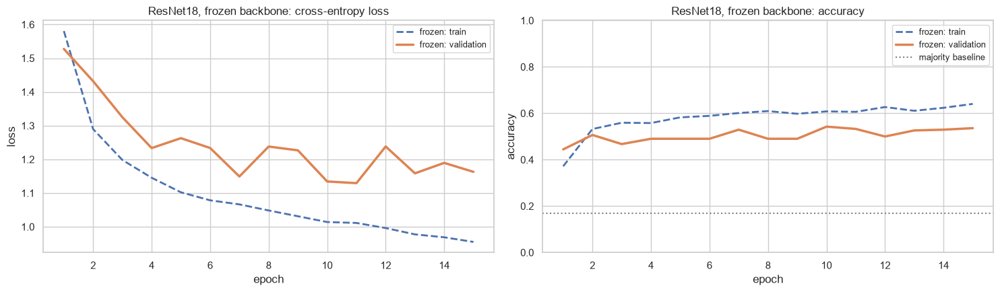

In [45]:
plot_history(history_frozen, "ResNet18, frozen backbone", "05_training_curves")

In [46]:
history_frozen.round(3)

,experiment,epoch,train_loss,val_loss,train_acc,val_acc,seconds
0,frozen,1,1.581,1.528,0.372,0.444,6.521
1,frozen,2,1.290,1.432,0.532,0.507,3.426
2,frozen,3,1.198,1.325,0.559,0.467,3.147
3,frozen,4,1.145,1.233,0.558,0.490,3.209
4,frozen,5,1.102,1.263,0.582,0.490,3.339
5,frozen,6,1.078,1.234,0.589,0.490,3.403
6,frozen,7,1.066,1.149,0.601,0.529,3.189
7,frozen,8,1.048,1.238,0.610,0.490,3.197
8,frozen,9,1.031,1.227,0.598,0.490,3.196
9,frozen,10,1.014,1.134,0.608,0.542,3.202


# 4. Look inside and diagnose

We use the **validation** set to understand the model **before** the test set is touched.

## 4.1 Predictions on the validation set

In [47]:
val_y, val_probs = predict(model, val_loader)
val_pred = val_probs.argmax(1)
print(f"{len(val_y)} validation images, {(val_pred == val_y).sum()} correct")
print("Validation:", {k: round(v, 3) for k, v in scores(val_y, val_pred).items()})

306 validation images, 163 correct
Validation: {'accuracy': 0.533, 'balanced accuracy': 0.537, 'macro F1': 0.517}


## 4.2 Confusion matrix

In [48]:
def plot_confusion(y_true, y_pred, title, name=None, model_card_name=None):
    matrix = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
    shares = matrix / matrix.sum(axis=1, keepdims=True).clip(min=1)
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(shares, annot=matrix, fmt="d", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES,
                cbar_kws={"label": "share of the true class"})
    plt.xlabel("predicted style")
    plt.ylabel("true style")
    plt.title(title)
    plt.tight_layout()
    if name:
        save_fig(name, model_card_name)
    plt.show()

Figure saved to ..\figures\06_confusion_matrix_val.png


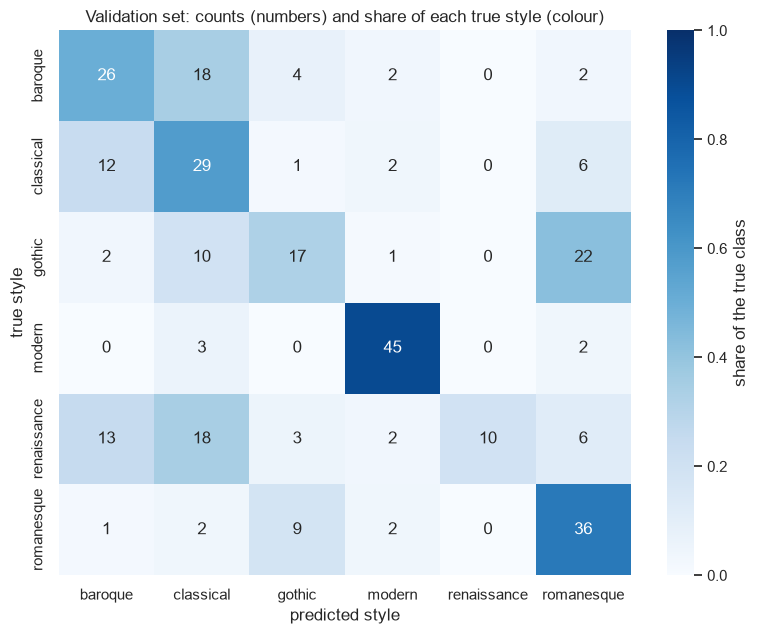

In [49]:
plot_confusion(val_y, val_pred, "Validation set: counts (numbers) and share of each true style (colour)", "06_confusion_matrix_val")

## 4.3 Precision and recall per class

In [50]:
def per_class_table(y_true, y_pred):
    p, r, f, n = precision_recall_fscore_support(y_true, y_pred, labels=range(len(CLASSES)), zero_division=0)
    return pd.DataFrame({"images": n, "precision": p, "recall": r, "F1": f}, index=CLASSES).round(3)


per_class_table(val_y, val_pred).sort_values("F1")

,images,precision,recall,F1
renaissance,52,1.000,0.192,0.323
gothic,52,0.500,0.327,0.395
classical,50,0.362,0.580,0.446
baroque,52,0.481,0.500,0.491
romanesque,50,0.486,0.720,0.581
modern,50,0.833,0.900,0.865


## 4.4 Gallery of misclassified images

What do the mistakes have in common? We show the validation images where the model was wrong, the **most confident** mistakes first.

In [51]:
def show_gallery(dataset, indices, y_true, probs, title, figure, n_cols=4, name=None, model_card_name=None):
    n_rows = int(np.ceil(len(indices) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4 * n_rows))
    for ax in np.atleast_1d(axes).flat:
        ax.set_axis_off()
    for ax, i in zip(np.atleast_1d(axes).flat, indices):
        path = Path(dataset.samples[i][0])
        pred = probs[i].argmax()
        ax.imshow(Image.open(path))
        ax.set_title(f"true: {CLASSES[y_true[i]]}\npredicted: {CLASSES[pred]} ({probs[i, pred]:.0%})",
                     color="darkgreen" if pred == y_true[i] else "firebrick", fontsize=11)
        credit(path.name, figure)
    plt.suptitle(title, fontsize=14, y=1.0)
    plt.tight_layout()
    if name:
        save_fig(name, model_card_name)
    plt.show()

143 of 306 validation images are misclassified; the 12 most confident mistakes:


Figure saved to ..\figures\07_misclassified_val.png and models/misclassified.png


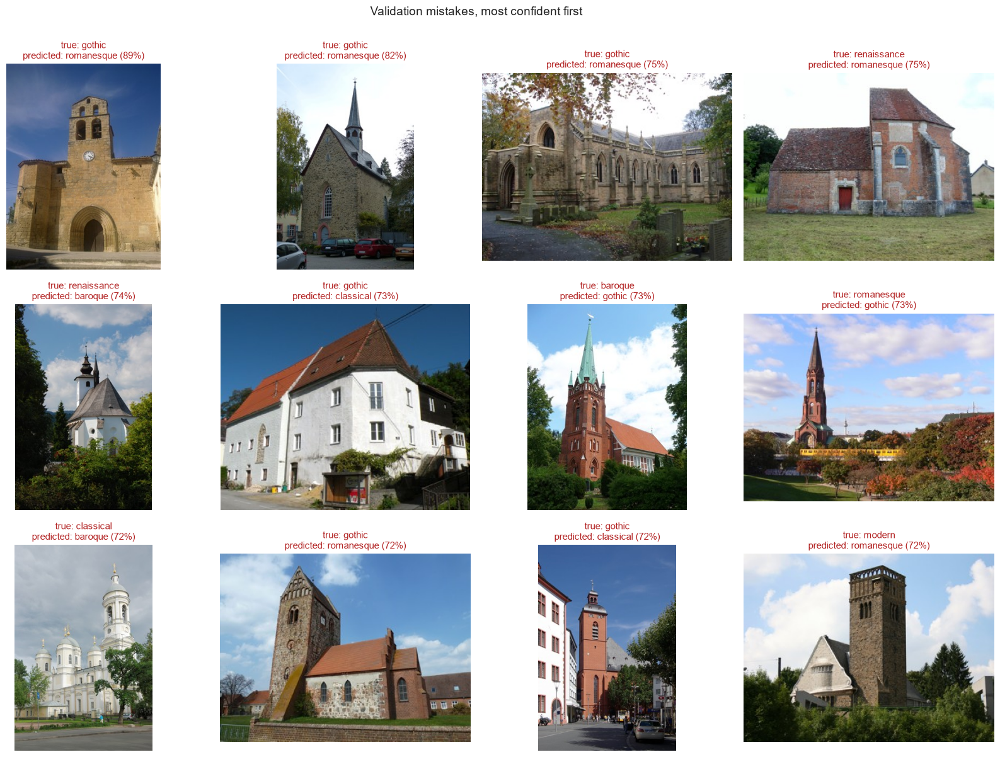

In [52]:
wrong = np.where(val_pred != val_y)[0]
wrong = wrong[np.argsort(-val_probs[wrong].max(1))][:12]
print(f"{(val_pred != val_y).sum()} of {len(val_y)} validation images are misclassified; the 12 most confident mistakes:")
show_gallery(val_ds, wrong, val_y, val_probs, "Validation mistakes, most confident first", "misclassified",
             name="07_misclassified_val", model_card_name="misclassified")

# 5. Tuning: two experiments on the validation set

Each experiment changes **one thing** and is compared with the main model on the **validation** set; the test set stays locked.

| Experiment | What changes | Why |
|---|---|---|
| **1. Class weights** | A weighted loss: mistakes on rare styles count more | Renaissance has only 64 training images against 300 for most classes |
| **2. Fine-tune `layer4`** | The deepest block of ResNet18 is unfrozen, with a 10× smaller learning rate (0.0001) | The deep features can adapt from ImageNet objects to architectural details |

We select the final model by **validation macro F1**, which treats every style equally. A helper collects the validation scores of each experiment:

In [53]:
def evaluate_on_val(model, name, history, minutes):
    y, probs = predict(model, val_loader)
    pred = probs.argmax(1)
    recall = precision_recall_fscore_support(y, pred, labels=range(len(CLASSES)), zero_division=0)[1]
    return {"experiment": name, **scores(y, pred), "recall renaissance": recall[CLASSES.index("renaissance")],
            "recall classical": recall[CLASSES.index("classical")], "best val loss": history["val_loss"].min(),
            "epochs": len(history), "minutes": minutes}


if TRAINING_RUN:
    results = [evaluate_on_val(frozen_model, "frozen", history_frozen, frozen_minutes)]
    histories = [history_frozen]
    trained = {"frozen": frozen_model}
    display(pd.DataFrame(results).set_index("experiment").round(3))

,accuracy,balanced accuracy,macro F1,recall renaissance,recall classical,best val loss,epochs,minutes
experiment,,,,,,,,
frozen,0.533,0.537,0.517,0.192,0.58,1.129,15,0.863


## 5.1 Experiment 1: class weights

Each class gets a weight inversely proportional to its number of training images.

In [54]:
class_counts = np.bincount(train_ds.targets, minlength=len(CLASSES))
class_weights = torch.tensor(class_counts.sum() / (len(CLASSES) * class_counts), dtype=torch.float32, device=DEVICE)
pd.DataFrame({"training images": class_counts, "weight": class_weights.cpu().numpy().round(2)}, index=CLASSES)

,training images,weight
baroque,300,0.86
classical,288,0.90
gothic,300,0.86
modern,300,0.86
renaissance,64,4.04
romanesque,300,0.86


In [55]:
if TRAINING_RUN:
    set_seed()
    weighted_model = build_model().to(DEVICE)
    start = time.time()
    history = train(weighted_model, torch.optim.Adam(weighted_model.fc.parameters(), lr=1e-3), epochs=20,
                    loss_fn=nn.CrossEntropyLoss(weight=class_weights), name="frozen + class weights")
    results.append(evaluate_on_val(weighted_model, "frozen + class weights", history, (time.time() - start) / 60))
    histories.append(history)
    trained["frozen + class weights"] = weighted_model
else:
    print("No training in this run: the results are loaded in section 5.3")

frozen + class weights epoch  1: train loss 1.641, acc 34.5% | val loss 1.375, acc 47.4%


frozen + class weights epoch  2: train loss 1.363, acc 50.0% | val loss 1.252, acc 51.3%


frozen + class weights epoch  3: train loss 1.273, acc 52.5% | val loss 1.164, acc 54.6%


frozen + class weights epoch  4: train loss 1.201, acc 54.6% | val loss 1.143, acc 55.9%


frozen + class weights epoch  5: train loss 1.172, acc 54.0% | val loss 1.134, acc 53.9%


frozen + class weights epoch  6: train loss 1.147, acc 56.1% | val loss 1.142, acc 53.9%


... (7 outputs left out)

frozen + class weights epoch 14: train loss 0.984, acc 61.5% | val loss 1.080, acc 55.9%


frozen + class weights epoch 15: train loss 1.004, acc 60.6% | val loss 1.082, acc 58.8%


frozen + class weights epoch 16: train loss 0.991, acc 62.0% | val loss 1.063, acc 61.4%


frozen + class weights epoch 17: train loss 0.978, acc 62.2% | val loss 1.099, acc 54.2%
Early stopping: no improvement for 4 epochs
Restored the weights of epoch 13 (validation loss 1.062)


## 5.2 Experiment 2: fine-tuning `layer4`

We start from the better of the two frozen models, unfreeze the last block and train both `layer4` and the last layer with a learning rate of 0.0001, as the brief suggests.

In [56]:
if TRAINING_RUN:
    use_weights = results[1]["macro F1"] > results[0]["macro F1"]
    start_name = "frozen + class weights" if use_weights else "frozen"
    finetuned_model = copy.deepcopy(trained[start_name])
    for p in finetuned_model.layer4.parameters():
        p.requires_grad = True
    trainable = sum(p.numel() for p in finetuned_model.parameters() if p.requires_grad)
    print(f"Starting from '{start_name}'; trainable parameters now: {trainable:,}")

Starting from 'frozen + class weights'; trainable parameters now: 8,396,806


In [57]:
if TRAINING_RUN:
    set_seed()
    name = f"{start_name} + fine-tuned layer4"
    optimizer = torch.optim.Adam([{"params": finetuned_model.layer4.parameters(), "lr": 1e-4},
                                  {"params": finetuned_model.fc.parameters(), "lr": 1e-4}])
    start = time.time()
    history = train(finetuned_model, optimizer, epochs=10, name=name,
                    loss_fn=nn.CrossEntropyLoss(weight=class_weights if use_weights else None))
    history["epoch"] += len(histories[[r["experiment"] for r in results].index(start_name)])   # continue the epoch count
    results.append(evaluate_on_val(finetuned_model, name, history, (time.time() - start) / 60))
    histories.append(history)
    trained[name] = finetuned_model
else:
    print("No training in this run: the results are loaded in section 5.3")

frozen + class weights + fine-tuned layer4 epoch  1: train loss 1.185, acc 54.3% | val loss 1.117, acc 55.2%


frozen + class weights + fine-tuned layer4 epoch  2: train loss 0.678, acc 73.7% | val loss 1.085, acc 57.5%


frozen + class weights + fine-tuned layer4 epoch  3: train loss 0.495, acc 82.9% | val loss 1.135, acc 56.2%


frozen + class weights + fine-tuned layer4 epoch  4: train loss 0.358, acc 87.7% | val loss 1.259, acc 55.6%


frozen + class weights + fine-tuned layer4 epoch  5: train loss 0.251, acc 92.3% | val loss 1.282, acc 56.2%


frozen + class weights + fine-tuned layer4 epoch  6: train loss 0.182, acc 95.7% | val loss 1.295, acc 54.6%
Early stopping: no improvement for 4 epochs
Restored the weights of epoch 2 (validation loss 1.085)


## 5.3 Comparing the experiments

### The table

In [58]:
if TRAINING_RUN:
    experiments = pd.DataFrame(results)
    all_history = pd.concat(histories, ignore_index=True)
    experiments.to_csv(EXPERIMENTS_PATH, index=False)
    all_history.to_csv(HISTORY_PATH, index=False)
else:
    experiments = pd.read_csv(EXPERIMENTS_PATH)
    all_history = pd.read_csv(HISTORY_PATH)

experiments.set_index("experiment").round(3)

,accuracy,balanced accuracy,macro F1,recall renaissance,recall classical,best val loss,epochs,minutes
experiment,,,,,,,,
frozen,0.533,0.537,0.517,0.192,0.58,1.129,15,0.863
frozen + class weights,0.595,0.594,0.586,0.712,0.26,1.062,17,0.918
frozen + class weights + fine-tuned layer4,0.575,0.576,0.577,0.500,0.36,1.085,6,0.324


### The training curves of all experiments

Figure saved to ..\figures\08_experiment_curves.png and models/training_curves.png


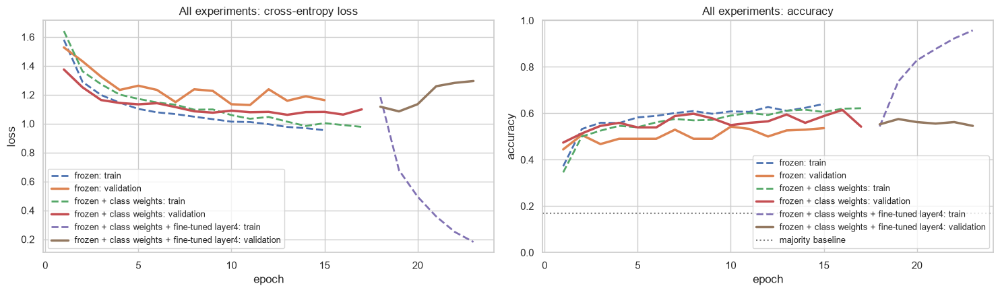

In [59]:
plot_history(all_history, "All experiments", "08_experiment_curves", "training_curves")

### The scores side by side

Figure saved to ..\figures\09_experiments.png


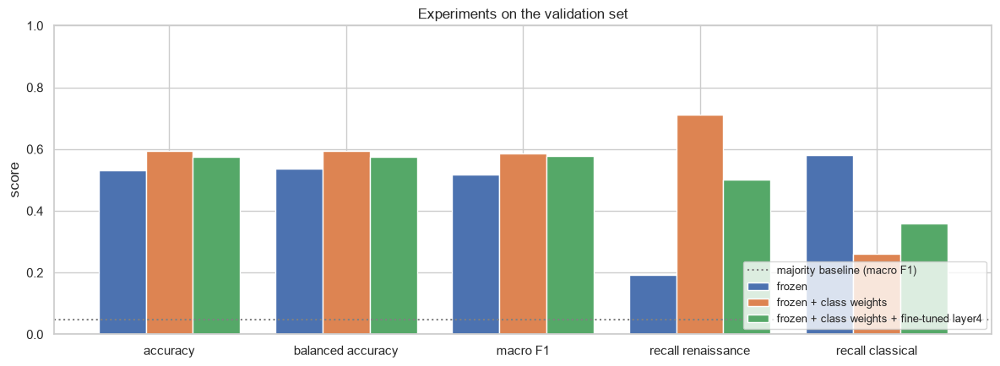

In [60]:
metrics = ["accuracy", "balanced accuracy", "macro F1", "recall renaissance", "recall classical"]
ax = experiments.set_index("experiment")[metrics].T.plot.bar(figsize=(12, 4.5), width=0.8, rot=0)
ax.axhline(baseline_val["macro F1"], color="grey", ls=":", label="majority baseline (macro F1)")
ax.set(title="Experiments on the validation set", ylabel="score", ylim=(0, 1))
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
save_fig("09_experiments")
plt.show()

### The final model

In [61]:
FINAL = experiments.loc[experiments["macro F1"].idxmax(), "experiment"]
if TRAINING_RUN:
    model = trained[FINAL]          # the selected model is used from here on
print("Selected by validation macro F1:", FINAL)
if TRAINING_RUN:
    # Save the selected weights immediately, before optional application downloads.
    temporary = WEIGHTS_PATH.with_suffix('.pt.tmp')
    torch.save(model.state_dict(), temporary)
    temporary.replace(WEIGHTS_PATH)
    (MODEL_DIR / "classes.json").write_text(json.dumps(CLASSES), encoding="utf-8")
    print("Exported selected checkpoint:", WEIGHTS_PATH.resolve())


Selected by validation macro F1: frozen + class weights
Exported selected checkpoint: D:\MaAI IAAC\Term 1\AI Methods\5-day4-assignment\models\model.pt


# 6. The test set, used once

The test set has stayed locked until now. We evaluate the **selected model** and the **majority baseline** on it, once.

## 6.1 Predictions on the test set

In [62]:
test_y, test_probs = predict(model, test_loader)
test_pred = test_probs.argmax(1)
baseline_pred = np.full_like(test_y, CLASSES.index(MAJORITY))
print(f"{len(test_y)} test images, {(test_pred == test_y).sum()} correct")

788 test images, 439 correct


## 6.2 Our network next to the baseline

In [63]:
test_results = pd.DataFrame({"majority baseline": scores(test_y, baseline_pred), f"ResNet18 ({FINAL})": scores(test_y, test_pred)})
test_results.round(3)

,majority baseline,ResNet18 (frozen + class weights)
accuracy,0.190,0.557
balanced accuracy,0.167,0.556
macro F1,0.053,0.551


Figure saved to ..\figures\10_test_vs_baseline.png and models/test_vs_baseline.png


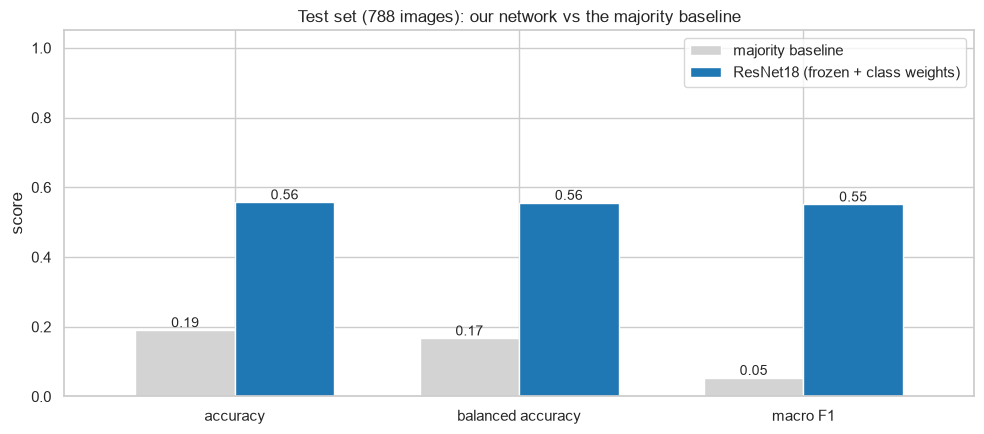

In [64]:
ax = test_results.plot.bar(figsize=(10, 4.5), rot=0, width=0.7, color=["lightgrey", "tab:blue"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=10)
ax.set(title=f"Test set ({len(test_y)} images): our network vs the majority baseline", ylabel="score", ylim=(0, 1.05))
plt.tight_layout()
save_fig("10_test_vs_baseline", "test_vs_baseline")
plt.show()

## 6.3 Confusion matrix and per-class scores

Figure saved to ..\figures\11_confusion_matrix_test.png and models/confusion_matrix.png


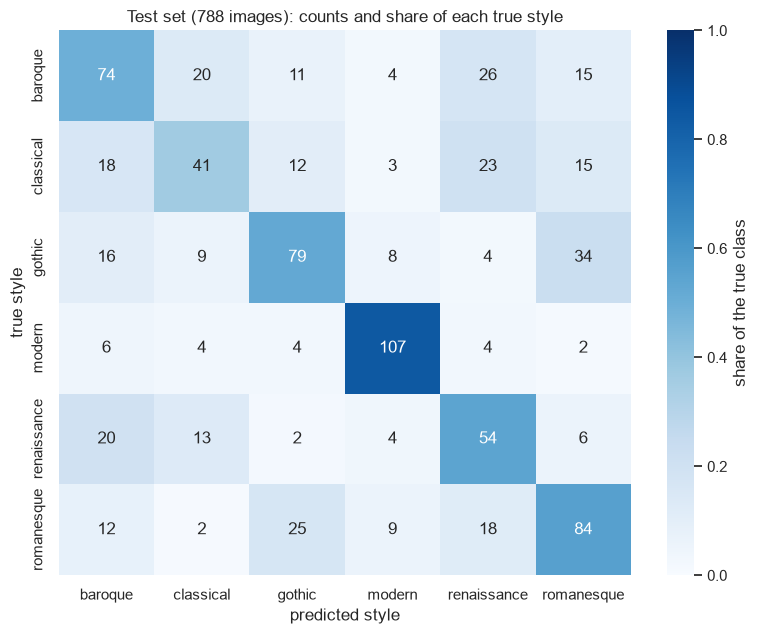

In [65]:
plot_confusion(test_y, test_pred, f"Test set ({len(test_y)} images): counts and share of each true style",
               "11_confusion_matrix_test", "confusion_matrix")

In [66]:
per_class_test = per_class_table(test_y, test_pred)
per_class_test.sort_values("F1")
test_results.to_csv(MODEL_DIR / "test_metrics.csv")
per_class_test.to_csv(MODEL_DIR / "per_class_test.csv")
run_metadata = {
    "selected_experiment": FINAL,
    "seed": RANDOM_STATE,
    "train_images": len(train_ds), "validation_images": len(val_ds), "test_images": len(test_ds),
    "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "torch_version": torch.__version__,
    "torchvision_version": __import__("torchvision").__version__,
    "python_version": __import__("platform").python_version(),
    "exported_at_utc": __import__("datetime").datetime.now(__import__("datetime").timezone.utc).isoformat(),
    "test_metrics": scores(test_y, test_pred),
    "baseline_metrics": scores(test_y, baseline_pred),
}
(MODEL_DIR / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2), encoding="utf-8")


660

## 6.4 What the model does: test images with the true and predicted style

A random selection of test images, **mistakes included** (red titles).

Figure saved to ..\figures\12_test_predictions.png and models/test_predictions.png


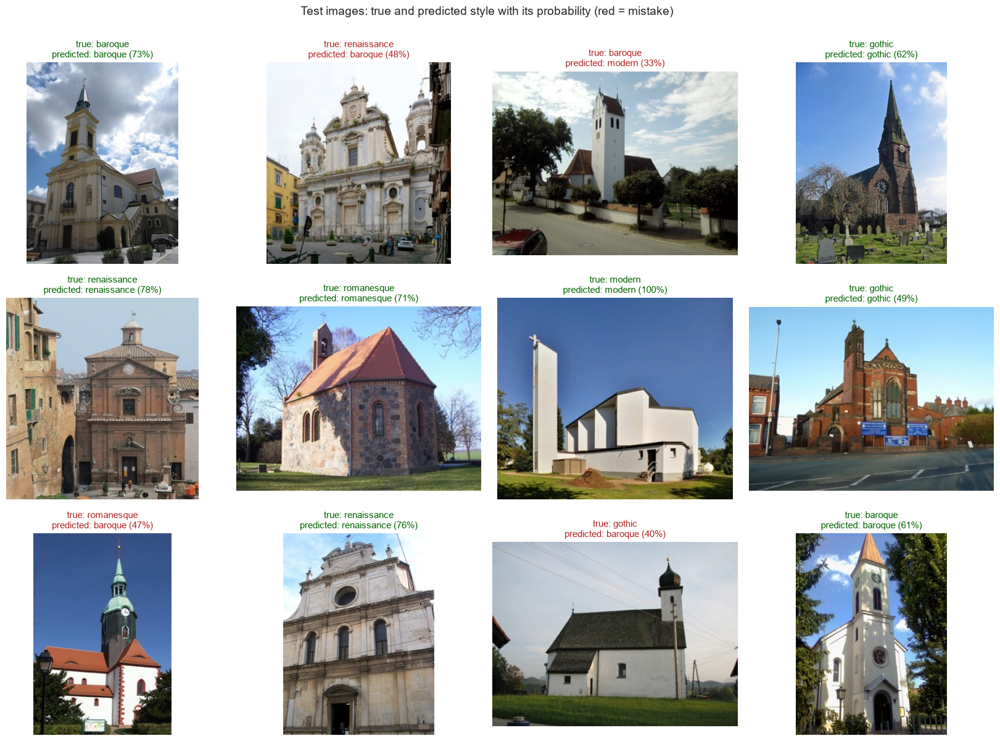

In [67]:
rng = np.random.default_rng(RANDOM_STATE)
right = rng.choice(np.where(test_pred == test_y)[0], 8, replace=False)
wrong_test = np.where(test_pred != test_y)[0]
mistakes = rng.choice(wrong_test, min(4, len(wrong_test)), replace=False)
selection = rng.permutation(np.concatenate([right, mistakes]))
show_gallery(test_ds, selection, test_y, test_probs, "Test images: true and predicted style with its probability (red = mistake)",
             "test_predictions", name="12_test_predictions", model_card_name="test_predictions")

# 7. Application: six new churches

The brief asks to run the model on **new images that are not in the dataset**. We chose six openly licensed photos from Wikimedia Commons, one per style, of churches that are **not in WikiChurches**. Four are in Barcelona, where we study.

The output is what the archive of our use case needs: the predicted style, its probability, and a **flag** for the photos an expert should check (top probability below 60 %).

## 7.1 The six churches

In [68]:
NEW_CHURCHES = pd.DataFrame([
    ("Q2101038", "Sant Pau del Camp, Barcelona", "romanesque", "Sant Pau del Camp - Absis.JPG"),
    ("Q6430822", "Basilica of Sts. Just and Pastor, Barcelona", "gothic", "166 Església dels Sants Just i Pastor, pl. Sant Just (Barcelona).jpg"),
    ("Q12960184", "Tempietto, Rome", "renaissance", "Tempietto di San Pietro in Montorio.jpg"),
    ("Q2037732", "Basilica of La Mercè, Barcelona", "baroque", "Basílica de la Mercè - Barcelona (Catalonia).jpg"),
    ("Q153816", "Rotunda of Mosta, Malta", "classical", "Rotonda de Mosta, isla de Malta, Malta, 2021-08-25, DD 84.jpg"),
    ("Q7889201", "US Air Force Academy Cadet Chapel, Colorado", "modern", "Air Force Academy Chapel, Colorado Springs, CO 04090u original.jpg"),
], columns=["wikidata", "church", "expected", "commons_file"])
REVIEW_THRESHOLD = 0.6

NEW_CHURCHES["in WikiChurches?"] = NEW_CHURCHES["wikidata"].isin(list(churches))
NEW_CHURCHES[["wikidata", "church", "expected", "in WikiChurches?"]]

,wikidata,church,expected,in WikiChurches?
0,Q2101038,"Sant Pau del Camp, Barcelona",romanesque,False
1,Q6430822,"Basilica of Sts. Just and Pastor, Barcelona",gothic,False
2,Q12960184,"Tempietto, Rome",renaissance,False
3,Q2037732,"Basilica of La Mercè, Barcelona",baroque,False
4,Q153816,"Rotunda of Mosta, Malta",classical,False
5,Q7889201,"US Air Force Academy Cadet Chapel, Colorado",modern,False


## 7.2 Download the photos with their author and licence

The Wikimedia Commons API gives the address of a 1,024-pixel version of each photo, its author and its licence.

In [69]:
def commons_info(file):
    for attempt in range(6):
        response = requests.get("https://commons.wikimedia.org/w/api.php", headers=HEADERS, timeout=60,
                                params={"action": "query", "titles": f"File:{file}", "prop": "imageinfo",
                                        "iiprop": "url|extmetadata", "iiurlwidth": 1024, "format": "json"})
        if response.ok:
            return next(iter(response.json()["query"]["pages"].values()))["imageinfo"][0]
        time.sleep(5 * (attempt + 1))
    response.raise_for_status()


rows = []
for church in NEW_CHURCHES.itertuples():
    info = commons_info(church.commons_file)
    path = download(info.get("thumburl") or info["url"], NEW_IMAGE_DIR / f"{church.wikidata}.jpg")
    rows.append({"path": path, "author": clean_html(info["extmetadata"].get("Artist", {}).get("value")),
                 "licence": info["extmetadata"].get("LicenseShortName", {}).get("value"), "source": info["descriptionurl"]})
    time.sleep(2)
new_df = pd.concat([NEW_CHURCHES, pd.DataFrame(rows)], axis=1)
new_df[["church", "author", "licence"]]

,church,author,licence
0,"Sant Pau del Camp, Barcelona",Josep Renalias,CC BY-SA 3.0
1,"Basilica of Sts. Just and Pastor, Barcelona",Enric,CC BY-SA 4.0
2,"Tempietto, Rome",Labicanense,CC BY 4.0
3,"Basilica of La Mercè, Barcelona",Puigalder,Public domain
4,"Rotunda of Mosta, Malta",Diego Delso,CC BY-SA 4.0
5,"US Air Force Academy Cadet Chapel, Colorado",Carol M. Highsmith,Public domain


## 7.3 Predict their style

In [70]:
set_train_mode(model, False)
with torch.no_grad():
    batch = torch.stack([eval_tf(ImageOps.exif_transpose(Image.open(p)).convert("RGB")) for p in new_df["path"]]).to(DEVICE)
    new_probs = torch.softmax(model(batch), dim=1).cpu().numpy()

top2 = np.argsort(-new_probs, axis=1)[:, :2]
new_df["predicted"] = [CLASSES[i] for i in top2[:, 0]]
new_df["probability"] = new_probs[np.arange(len(new_df)), top2[:, 0]]
new_df["second guess"] = [f"{CLASSES[j]} ({new_probs[k, j]:.0%})" for k, j in enumerate(top2[:, 1])]
new_df["action"] = np.where(new_df["probability"] < REVIEW_THRESHOLD, "check by an expert", "accept")
new_df[["church", "expected", "predicted", "probability", "second guess", "action"]].round(2)
new_df.to_csv(MODEL_DIR / "new_church_predictions.csv", index=False)


## 7.4 The result as a figure

Figure saved to ..\figures\13_new_churches.png and models/new_churches.png


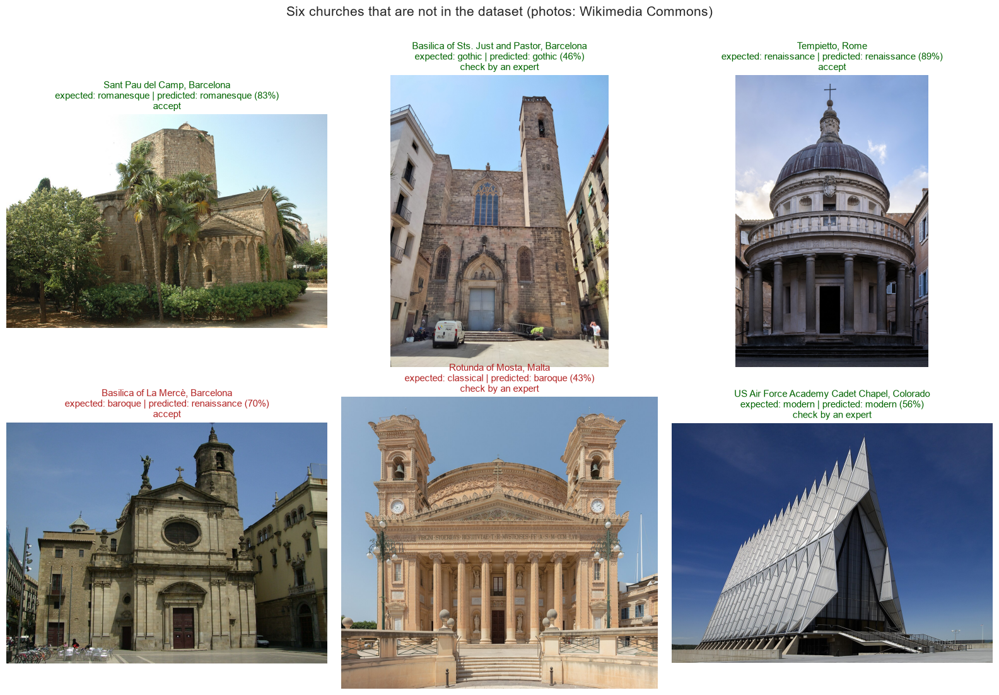

In [71]:
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, row in zip(axes.flat, new_df.itertuples()):
    ax.imshow(ImageOps.exif_transpose(Image.open(row.path)))
    ax.set_axis_off()
    ax.set_title(f"{row.church}\nexpected: {row.expected} | predicted: {row.predicted} ({row.probability:.0%})\n{row.action}",
                 color="darkgreen" if row.predicted == row.expected else "firebrick", fontsize=11)
    FIGURE_CREDITS.append({"figure": "new_churches", "file": row.commons_file, "author": row.author,
                           "licence": row.licence, "source": row.source})
plt.suptitle("Six churches that are not in the dataset (photos: Wikimedia Commons)", fontsize=15, y=1.0)
plt.tight_layout()
save_fig("13_new_churches", "new_churches")
plt.show()

# 8. Save, reload and use

## 8.1 Save the weights and the class order

A `state_dict` contains only the numbers. To use it, one must **rebuild the same architecture** and apply the **same preprocessing**: both go into the model card.

In [72]:
if TRAINING_RUN:
    torch.save(model.state_dict(), WEIGHTS_PATH)
(MODEL_DIR / "classes.json").write_text(json.dumps(CLASSES))
print(f"{WEIGHTS_PATH} ({WEIGHTS_PATH.stat().st_size / 1e6:.0f} MB), classes: {CLASSES}")

..\models\model.pt (45 MB), classes: ['baroque', 'classical', 'gothic', 'modern', 'renaissance', 'romanesque']


## 8.2 Reload in a new object and predict one image, as a user would

In [73]:
reloaded = models.resnet18()                                     # the same architecture...
reloaded.fc = nn.Linear(reloaded.fc.in_features, len(CLASSES))   # ...with the same last layer
reloaded.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
reloaded.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [74]:
transform = models.ResNet18_Weights.DEFAULT.transforms()         # the same preprocessing as in training
example_path, example_label = test_ds.samples[0]
with torch.no_grad():
    probabilities = torch.softmax(reloaded(transform(Image.open(example_path).convert("RGB")).unsqueeze(0)), dim=1)[0]

print("True style:", CLASSES[example_label])
print({c: round(p, 3) for c, p in zip(CLASSES, probabilities.tolist())})
print("Same prediction as before saving:", np.allclose(probabilities.numpy(), test_probs[0], atol=1e-3))

True style: baroque
{'baroque': 0.158, 'classical': 0.105, 'gothic': 0.028, 'modern': 0.003, 'renaissance': 0.496, 'romanesque': 0.21}
Same prediction as before saving: True


## 8.3 Export the figure credits

Every photo shown in a figure has an author and a licence. The list goes to `models/figure_credits.csv` (uploaded with the model card) and `figures/figure_credits.csv`.

In [75]:
figure_credits = pd.DataFrame(FIGURE_CREDITS).drop_duplicates(["figure", "file"])
for folder in [MODEL_DIR, FIG_DIR]:
    figure_credits.to_csv(folder / "figure_credits.csv", index=False)
print(f"{len(figure_credits)} credited photos; licences:", figure_credits["licence"].value_counts().to_dict())

61 credited photos; licences: {'CC BY-SA 3.0': 28, 'CC BY-SA 4.0': 7, 'CC BY 3.0': 5, 'Public domain': 5, 'CC-BY-SA-3.0': 4, 'CC BY-SA 3.0 at': 3, 'CC BY-SA 2.0': 2, 'CC BY-SA 3.0 de': 1, 'CC BY 2.0': 1, 'CC BY-SA 3.0 es': 1, 'Copyrighted free use': 1, 'FAL': 1, 'CC BY-SA 2.5': 1, 'CC BY 4.0': 1}


In [76]:
print("Files for Hugging Face in models/:")
for path in sorted(MODEL_DIR.iterdir()):
    print(f"  {path.name:<26} {path.stat().st_size / 1e6:6.2f} MB")

Files for Hugging Face in models/:
  class_examples.png           5.57 MB
  classes.json                 0.00 MB
  confusion_matrix.png         0.08 MB
  experiments.csv              0.00 MB
  figure_credits.csv           0.01 MB
  melbourne_best_model.joblib  86.29 MB
  melbourne_house_gradient_boosting.joblib   2.20 MB
  melbourne_house_mlp.pt       0.03 MB
  melbourne_house_mlp_preprocessing.joblib   0.00 MB
  misclassified.png            3.71 MB
  model.pt                    44.79 MB
  new_church_predictions.csv   0.00 MB
  new_churches.png             4.10 MB
  per_class_test.csv           0.00 MB
  README.md                    0.01 MB
  run_metadata.json            0.00 MB
  test_metrics.csv             0.00 MB
  test_predictions.png         3.65 MB
  test_vs_baseline.png         0.04 MB
  training_curves.png          0.16 MB
  training_history.csv         0.00 MB


# 9. Conclusions

## Key findings

- The exported frozen + class weights checkpoint reaches 55.7% test accuracy, balanced accuracy 0.556, and macro F1 0.551 on 788 held-out images.
- The majority baseline reaches 19.0% accuracy and macro F1 0.053.
- The strongest class is modern, with test F1 0.817.
- Validation macro F1 selected the final experiment before test evaluation. Full comparisons are saved in `models/experiments.csv`.
- The weights were exported immediately after selection and validated by strict reload and real-image inference. Run details and checksum are in `models/run_metadata.json`.

## Limitations and biases

- **Only churches, mostly European.** WikiChurches covers church exteriors from Wikidata, mostly in Germany and neighbouring countries (section 1.7). The model knows nothing about other building types and little about churches from other regions.
- **Six broad styles.** Revival styles (Neo-Gothic, Neo-Romanesque), regional variants and buildings with several building phases are forced into one of six classes; the labels come from Wikidata and were not checked by experts.
- **Photos from Wikipedia.** Mostly sunny, frontal, daytime photos of whole buildings; interiors, details, night or drone views are rare.
- **A subset.** We used 2,646 of 8,488 images (section 1.4); the test set (788 images) gives scores that are uncertain by a few points, and the rare classes have only about 100 test images.

## What the model must not be used for

- Dating or attributing a specific building, or any heritage-protection decision without an expert.
- Buildings that are not churches, or images that are not exterior photos.